 ## 3a Create a new Jupyter Notebook and test the code presented in today’s material.

In [1]:
from keras.preprocessing.image import ImageDataGenerator

data_gen = ImageDataGenerator(rotation_range=30,
                             width_shift_range=0.2,
                             height_shift_range=0.2,
                             horizontal_flip=True,
                             zoom_range=0.2)

In [2]:
import numpy as np

def GenerateImages(generator, image, num_images):
    new_images = []
    # we need to reshape the image because the generator.flow() 
    # expects an array of images
    image = np.reshape(image, (1,) + image.shape)
    for _ in range(num_images):
        batch = next(generator.flow(image, batch_size=1))
        new_images.append(batch[0])
    return np.array(new_images)

In [4]:
import skimage as ski
image = ski.io.imread("BUas_1.png")
image = ski.util.img_as_float(image)
augmented_images = GenerateImages(data_gen, image, 9)

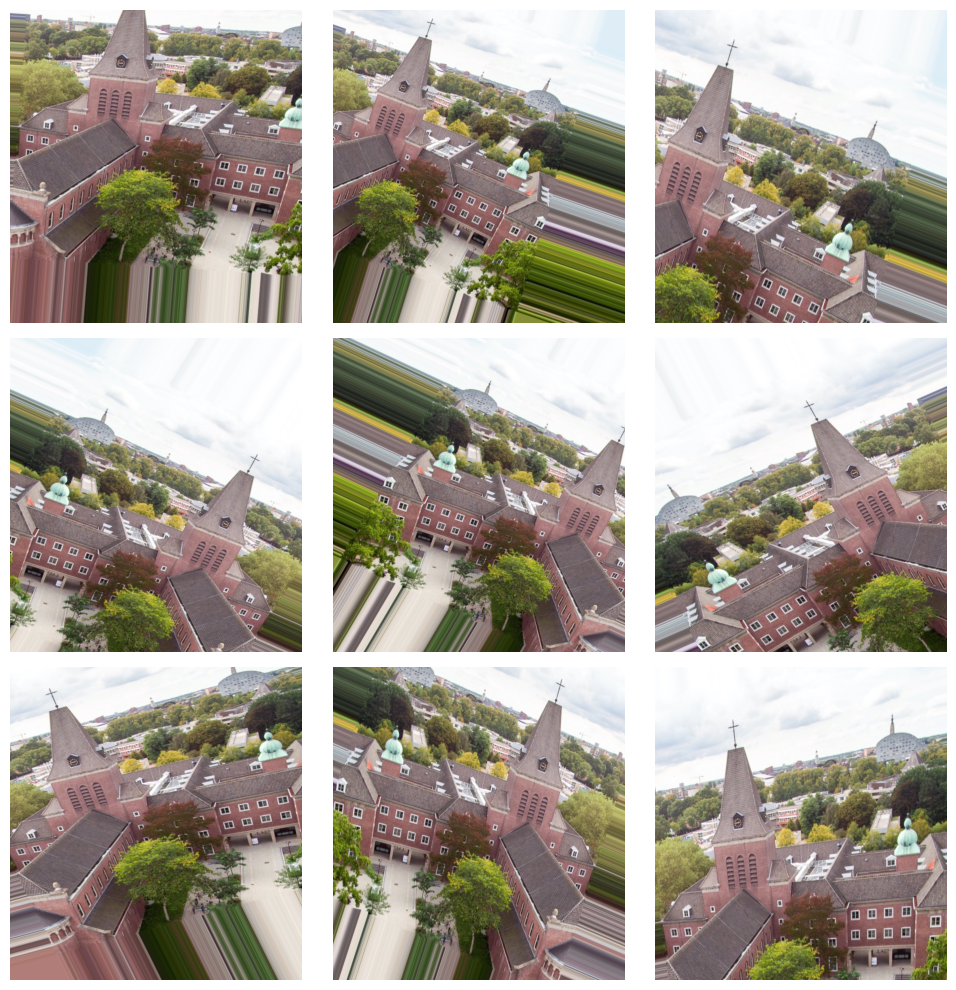

In [6]:
import matplotlib.pyplot as plt
import math

num_images = len(augmented_images)
grid_size = int(math.ceil(math.sqrt(num_images)))

fig, axes = plt.subplots(nrows=grid_size, ncols=grid_size, figsize=(10, 10))
axes = axes.flatten()

for i in range(grid_size * grid_size):
    if i < num_images:
        axes[i].imshow(augmented_images[i])
        axes[i].axis('off')
    else:
        axes[i].axis('off')   
        
plt.tight_layout()
plt.show()

## 3b Apply data augmentation in a single image from the dataset of your creative brief project. Generate 16 new images. Show the generated images using matplotlib.

In [8]:
import keras
from keras import layers
import numpy as np
import tensorflow as tf

data_augmentation = tf.keras.Sequential([
  layers.RandomFlip("horizontal_and_vertical"),
  layers.RandomRotation(0.2),
])

In [15]:
import keras
from keras import layers
import numpy as np

data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.2),
    ]
)
image = ski.io.imread("Fresh orange.jpg")
image = ski.util.img_as_float(image)


image = np.reshape(image, (1,) + image.shape)

augmented_images = []
num_images = 16
for _ in range(num_images):
    augmented = data_augmentation(image)
    augmented_images.append(augmented[0])

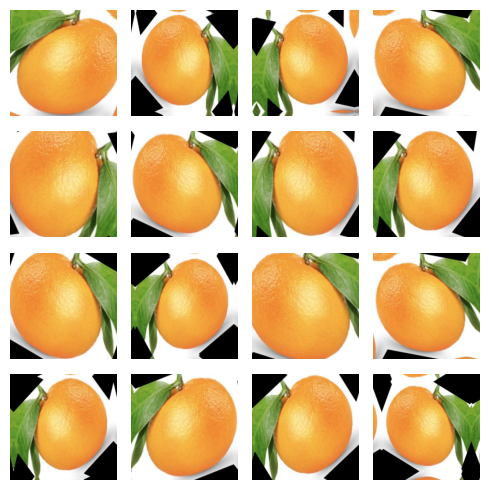

In [18]:
import matplotlib.pyplot as plt

num_images = len(augmented_images)
grid_size = int(math.ceil(math.sqrt(num_images)))

fig, axes = plt.subplots(nrows=grid_size, ncols=grid_size, figsize=(5, 5))
axes = axes.flatten()

for i in range(grid_size * grid_size):
    if i < num_images:
        axes[i].imshow(augmented_images[i])
        axes[i].axis('off')
    else:
        axes[i].axis('off')   
        
plt.tight_layout()
plt.show()